### Ferroni Sandro
### Gassem Aymen

# Projet IREN : Heart Failure

Dans ce projet nous allons essayer de prédire la mort ou non d'un patient par crise cardiaque en fonction de certaines données médicales.

## Traitement et analyse des données

Nous allons dans un premier temps récupérer le jeu de données disponible sur : 
    https://huggingface.co/datasets/mstz/heart_failure

In [1]:
from datasets import load_dataset

dataset = load_dataset("mstz/heart_failure", "death")["train"]

/home/sandro/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


On va ensuite mettre ce Dataset en pandas et vérifier si des valeurs sont manquantes.

In [2]:
import pandas as pd
df = pd.DataFrame(dataset) # Convertie en pandas DF
print(df.isnull().sum()) # 1ffiche le nombre de valeur null pour chaque colonne
df

age                                                0
has_anaemia                                        0
creatinine_phosphokinase_concentration_in_blood    0
has_diabetes                                       0
heart_ejection_fraction                            0
has_high_blood_pressure                            0
platelets_concentration_in_blood                   0
serum_creatinine_concentration_in_blood            0
serum_sodium_concentration_in_blood                0
is_male                                            0
is_smoker                                          0
days_in_study                                      0
is_dead                                            0
dtype: int64


,age,has_anaemia,creatinine_phosphokinase_concentration_in_blood,has_diabetes,heart_ejection_fraction,has_high_blood_pressure,platelets_concentration_in_blood,serum_creatinine_concentration_in_blood,serum_sodium_concentration_in_blood,is_male,is_smoker,days_in_study,is_dead
0,75,False,582.0,False,20.0,True,265000.00,1.9,130.0,True,False,4,1
1,55,False,7861.0,False,38.0,False,263358.03,1.1,136.0,True,False,6,1
2,65,False,146.0,False,20.0,False,162000.00,1.3,129.0,True,True,7,1
3,50,True,111.0,False,20.0,False,210000.00,1.9,137.0,True,False,7,1
4,65,True,160.0,True,20.0,False,327000.00,2.7,116.0,False,False,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62,False,61.0,True,38.0,True,155000.00,1.1,143.0,True,True,270,0
295,55,False,1820.0,False,38.0,False,270000.00,1.2,139.0,False,False,271,0
296,45,False,2060.0,True,60.0,False,742000.00,0.8,138.0,False,False,278,0
297,45,False,2413.0,False,38.0,False,140000.00,1.4,140.0,True,True,280,0


On constate qu'aucune valeur n'est manquante dans notre jeu de données. Cependant, comme on peut le voir ci-dessous, certaines colonnes sont de type Boolean ce qui ne peut pas fonctionner dans le cadre de notre projet.

In [3]:
df.dtypes

age                                                  int64
has_anaemia                                           bool
creatinine_phosphokinase_concentration_in_blood    float64
has_diabetes                                          bool
heart_ejection_fraction                            float64
has_high_blood_pressure                               bool
platelets_concentration_in_blood                   float64
serum_creatinine_concentration_in_blood            float64
serum_sodium_concentration_in_blood                float64
is_male                                               bool
is_smoker                                             bool
days_in_study                                        int64
is_dead                                              int64
dtype: object

On va donc transformer nos données de type bool en des types int :

In [4]:
df['has_anaemia'] = df['has_anaemia'].astype(int) # Convertie en int: 0=False, 1=True
df['has_diabetes'] = df['has_diabetes'].astype(int)
df['has_high_blood_pressure'] = df['has_high_blood_pressure'].astype(int)
df['is_male'] = df['is_male'].astype(int)
df['is_smoker'] = df['is_smoker'].astype(int)
df.dtypes

age                                                  int64
has_anaemia                                          int64
creatinine_phosphokinase_concentration_in_blood    float64
has_diabetes                                         int64
heart_ejection_fraction                            float64
has_high_blood_pressure                              int64
platelets_concentration_in_blood                   float64
serum_creatinine_concentration_in_blood            float64
serum_sodium_concentration_in_blood                float64
is_male                                              int64
is_smoker                                            int64
days_in_study                                        int64
is_dead                                              int64
dtype: object

Voici ainsi notre DataSet au complet.

In [5]:
df

,age,has_anaemia,creatinine_phosphokinase_concentration_in_blood,has_diabetes,heart_ejection_fraction,has_high_blood_pressure,platelets_concentration_in_blood,serum_creatinine_concentration_in_blood,serum_sodium_concentration_in_blood,is_male,is_smoker,days_in_study,is_dead
0,75,0,582.0,0,20.0,1,265000.00,1.9,130.0,1,0,4,1
1,55,0,7861.0,0,38.0,0,263358.03,1.1,136.0,1,0,6,1
2,65,0,146.0,0,20.0,0,162000.00,1.3,129.0,1,1,7,1
3,50,1,111.0,0,20.0,0,210000.00,1.9,137.0,1,0,7,1
4,65,1,160.0,1,20.0,0,327000.00,2.7,116.0,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62,0,61.0,1,38.0,1,155000.00,1.1,143.0,1,1,270,0
295,55,0,1820.0,0,38.0,0,270000.00,1.2,139.0,0,0,271,0
296,45,0,2060.0,1,60.0,0,742000.00,0.8,138.0,0,0,278,0
297,45,0,2413.0,0,38.0,0,140000.00,1.4,140.0,1,1,280,0


On peut maintenant regarder cette matrice de corrélation dans le but de connaitre nos données les plus influentes.

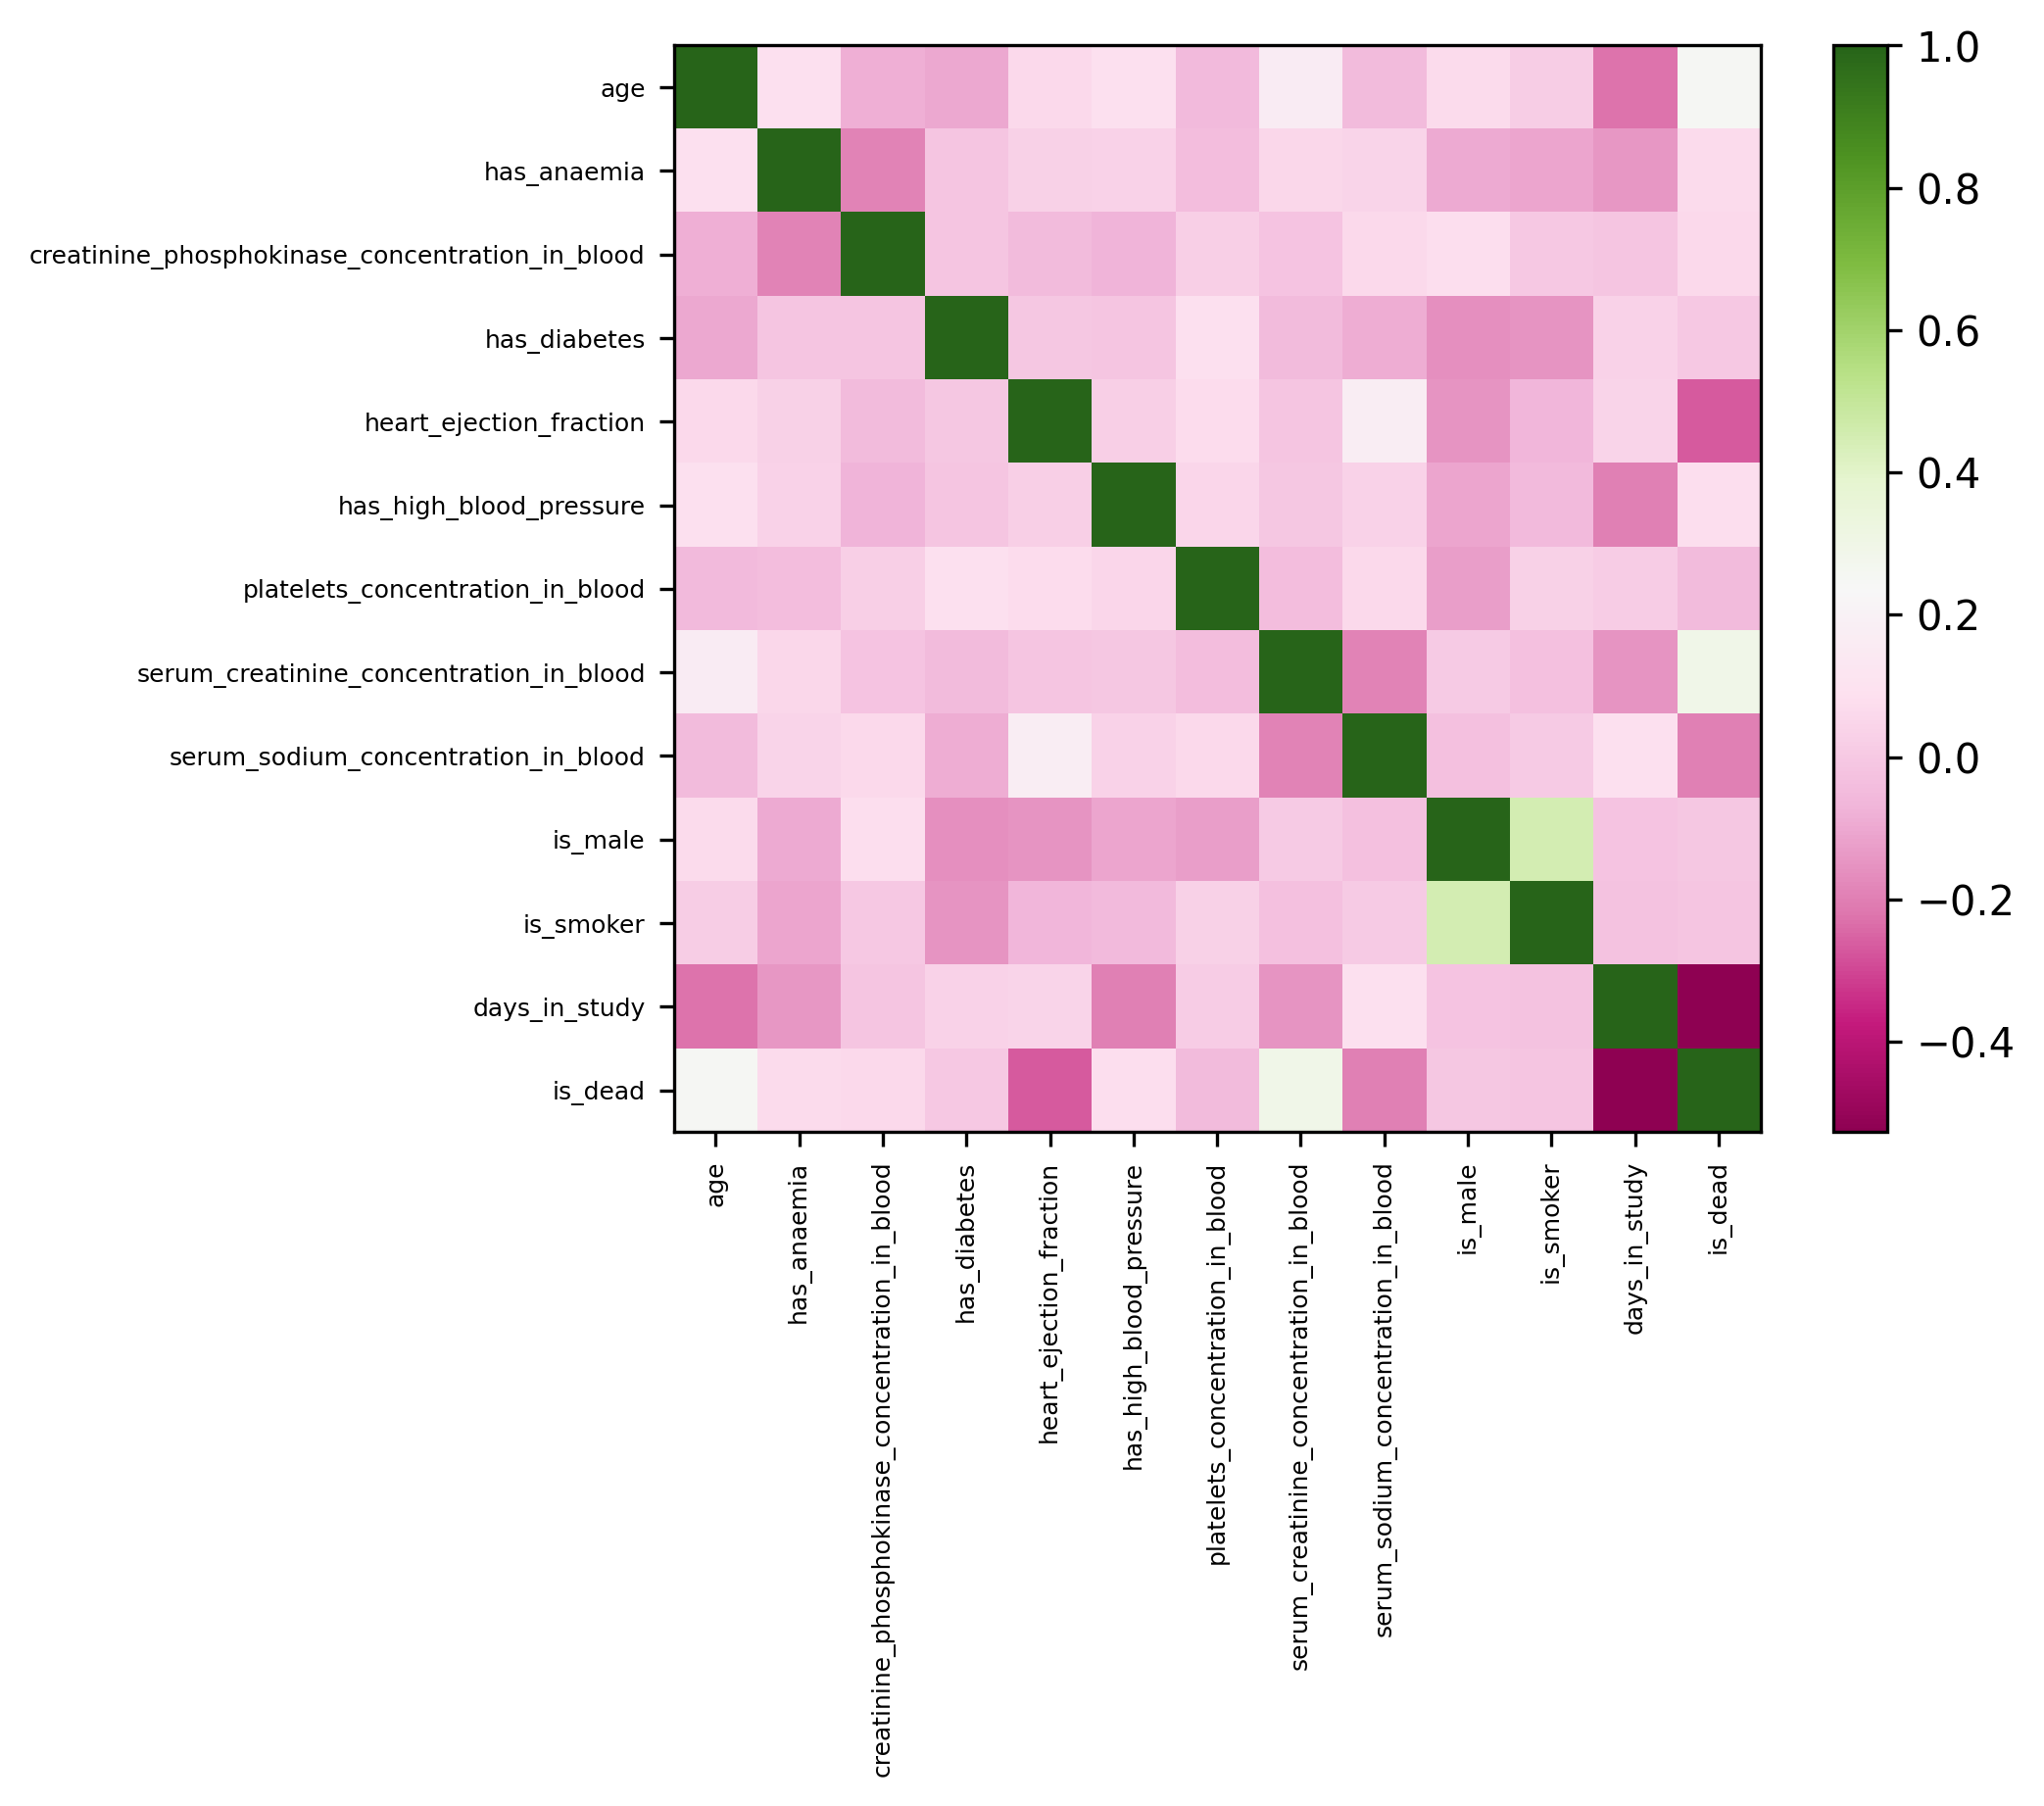

In [6]:
import matplotlib.pyplot as plt
plt.figure(dpi=300)
plt.imshow(df.corr(), cmap=plt.get_cmap("PiYG"))
plt.xticks(range(len(df.columns)),df.columns, fontsize=6, rotation=90)
plt.yticks(range(len(df.columns)),df.columns, fontsize=6)
plt.colorbar()

On constate une corrélation entre la mort d'un patient et le nombre de jours pour lesquels nous avons étudié ce patient. Or, cette dernière est due aux potentiels états du patient. Le nombre de jours d'étude n'influence pas concrètement la mort de celui-ci.
On va donc enlever cette colonne.

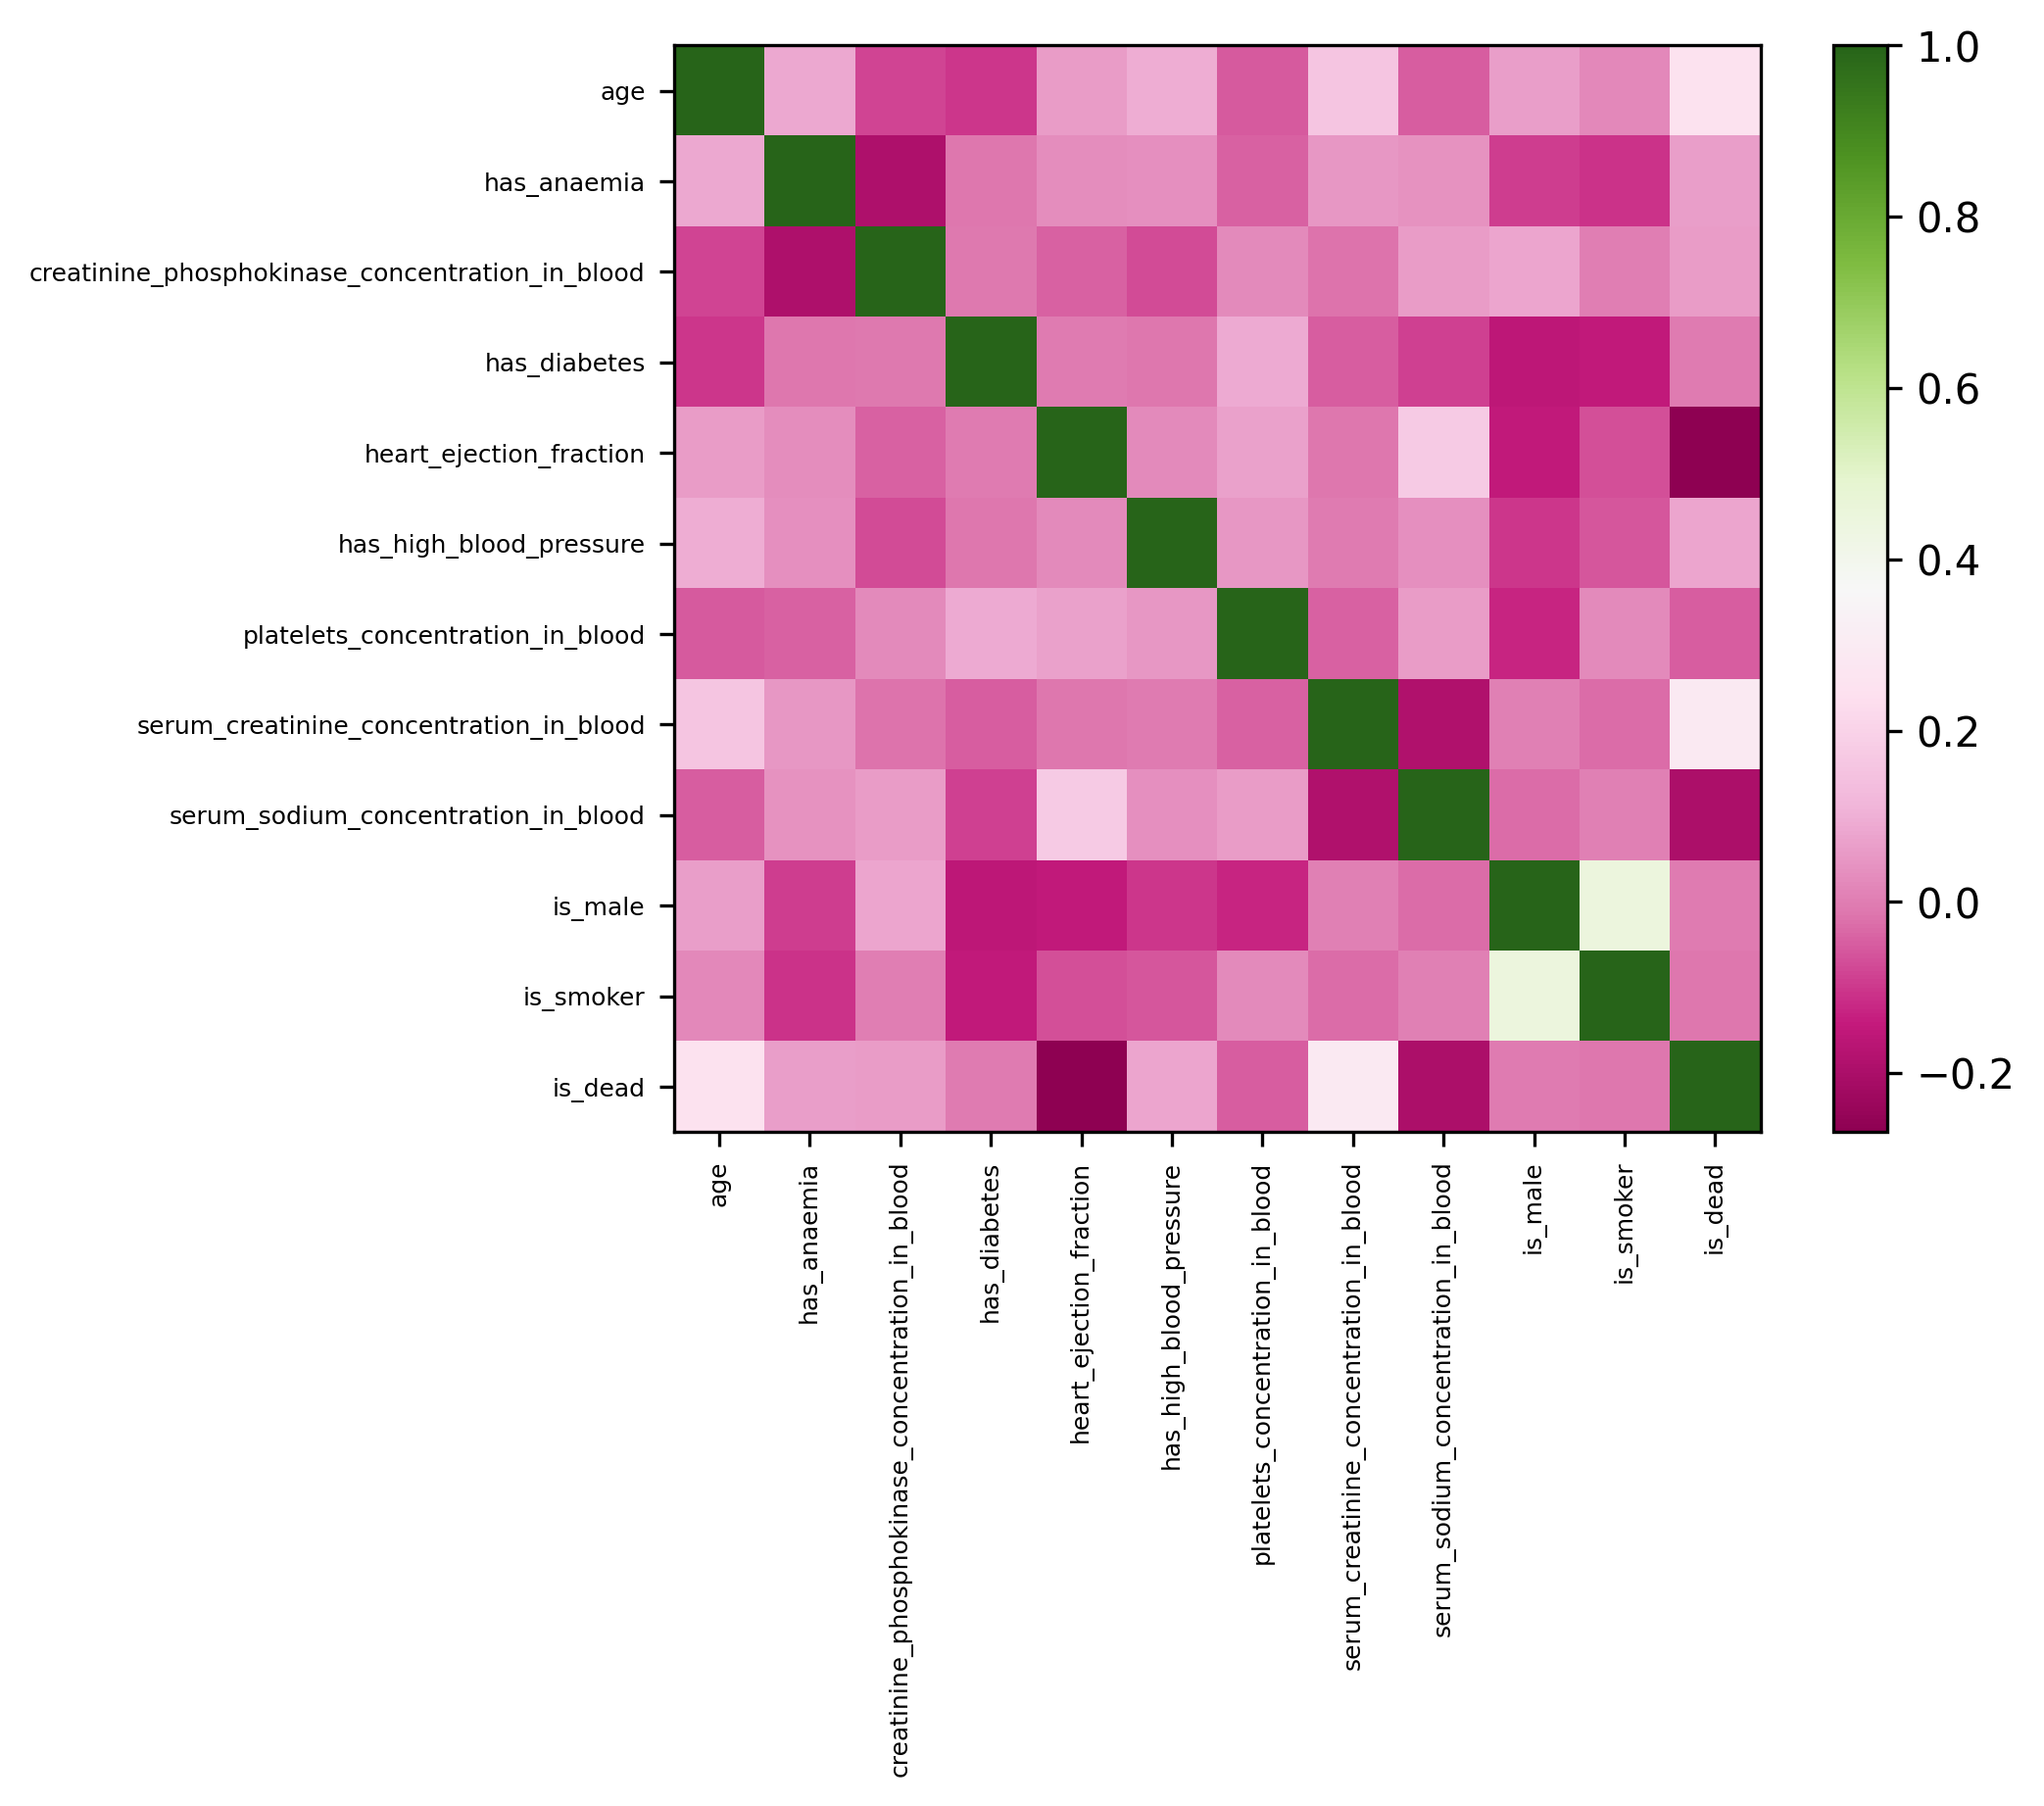

In [7]:
data = df.drop(columns=["days_in_study"]) # Suppression de la colonne
# MAtrice de correlation
plt.figure(dpi=300)
plt.imshow(data.corr(), cmap=plt.get_cmap("PiYG"))
plt.xticks(range(len(data.columns)),data.columns, fontsize=6, rotation=90)
plt.yticks(range(len(data.columns)),data.columns, fontsize=6)
plt.colorbar()

On obtient ainsi cette matrice de corrélation.

## Choix du modèle

Dans un premier temps, nous allons séparer nos données entre les entrées et la sortie, la mort ou non du patient à prédire.

In [8]:
features = data.drop(columns=["is_dead"]).values # input
labels = data["is_dead"].values # output

Nous créons ensuite un modèle. 
Comme il s'agit d'une classification binaire, nous utilisons une architecture composée de plusieurs couches linéaires (densely connected layers) avec des fonctions d'activation non linéaires. 
Nous avons opté pour 4 couches linéaires, et avons choisi la fonction d'activation ReLU en raison de ses performances intéressantes en réseau de neurones. La fonction d'activation Sigmoid assure la binarité de notre prédiction (0 ou 1).

In [9]:
import torch
from torch import nn

class HeartFailureModel(nn.Module):
    def __init__(self, input_dim):
        super(HeartFailureModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64), # représente en 64 dim pour avoir des données plus complexes
            nn.ReLU(), # introduit une non-linéarité
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


On initialise une fonction qui nous permettra d'afficher nos valeurs pour pouvoir comparer et choisir notre meilleur modèle.

In [10]:
def Print_loss_accuracy(nepoch, tloss, vloss, accuracy, best_tloss, best_vloss, best_accuracy, auc):
    print ("{:<6} {:<15} {:<17} {:<15} {:<20} {:<22} {:<15} {:<9}".format(nepoch, tloss, vloss, accuracy, best_tloss, best_vloss, best_accuracy, auc))

On utilise la fonction Learning utilisée dans le TP2 dans le but d'entrainer et d'évaluer notre modèle à plusieurs epoch.

In [11]:
from sklearn.metrics import roc_auc_score
import numpy as np
from torch.utils.tensorboard import SummaryWriter

# Entraînement et validation
def Learning(nepoch, model, crit, optim, batchsize, trainingloader, validationloader):
    best_tloss = 100. # perte d'entrainement
    best_vloss = 100. # perte de validation
    best_accuracy = 0. # meilleur précision
    writer = SummaryWriter()
    Print_loss_accuracy('Epoch', 'training loss', 'validation loss', 'accuracy', 'best train loss', 'best validation loss', 'best accuracy', "ROC AUC")

    for nepoch in range(nepoch): # On boucle sur chaque epoch
        tloss = 0.
        vloss = 0.
        correct_test = 0
        y_scores = []
        y_true = []
        model.train()
        for X_batch, y_batch in trainingloader: # Training
            optim.zero_grad()
            predicted = model(X_batch.float())
            loss = crit(predicted, y_batch.float())
            loss.backward()
            optim.step()
            tloss += loss.item() * X_batch.size(0)
        tloss /= len(trainingloader.dataset)
        total = 0
        model.eval()
        with torch.no_grad():
            for X_batch, y_batch in validationloader: # Validation
                predicted = model(X_batch.float())
                loss = crit(predicted, y_batch.float())
                vloss += loss.item() * X_batch.size(0)
                predicted = torch.sigmoid(predicted)
                predicted = (predicted > 0.5).float()
                total += y_batch.size(0)
                correct_test += (predicted == y_batch).sum().item()
                y_true.extend(y_batch.numpy())
                y_scores.extend(predicted.numpy())
        
        vloss /= len(validationloader.dataset)
        accuracy = 100 * correct_test / total
        auc = roc_auc_score(y_true, y_scores)

        writer.add_scalar("Loss/Training", tloss, nepoch) # On ecrit nos données dans TensorBoard
        writer.add_scalar("Loss/Validation", vloss, nepoch)
        writer.add_scalar("Accuracy", accuracy, nepoch)
        writer.add_scalar("ROC AUC", auc, nepoch)
            
        if accuracy >= best_accuracy:
            torch.save(model, "best_model.pth")
            best_accuracy=accuracy
        if vloss <= best_vloss:
            best_vloss = vloss
        if tloss <= best_tloss:
            best_tloss = tloss
        Print_loss_accuracy(nepoch+1, 
                            np.round(tloss,8), 
                            np.round(vloss,8), 
                            np.round(accuracy,8), 
                            np.round(best_tloss,8), 
                            np.round(best_vloss,8), 
                            np.round(best_accuracy,8),
                            np.round(auc, 8))
    
    writer.close()
    return [best_accuracy, best_vloss, best_tloss, model] # On retourne nos meilleurs données de pertes et précision

On va ainsi séparer notre jeu de données en 2, une partie d'entrainement et une partie de validation avec un ratio de 80% et 20%, répartis de manière aléatoire.

In [12]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # Normalisation des données
features = scaler.fit_transform(features)

X = torch.tensor(features, dtype=torch.float32) # Convertire en tensor PyTorch
y = torch.tensor(labels, dtype=torch.float32).unsqueeze(1)

# Diviser les données en ensembles d'entraînement et de validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Créer les DataLoaders
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

Nous allons initialiser nos différentes données que nous allons utiliser : 

 - criterion : BCEWithLogitsLoss correspond à la perte de la cross-entropy binaire avec logits, couramment utilisée pour les tâches de classification binaire et prend en charge à la fois les valeurs de sortie et les probabilités, elle combine la fonction sigmoïde et la fonction BCELoss en une seule fonction, elle peut aider à éviter les problèmes de stabilité numérique lors du calcul des logarithmes dans la BCELoss et souvent un des meilleurs choix pour les tâches de classification binaire.
 - optimizers : sont couramment utilisés dans l'entraînement de réseaux de neurones et chacun a ses propres avantages et inconvénients. Ils seront utilisés pour comparer leurs performances lors de l'entraînement du modèle, dans le but de découvrir les hyperparamètres correspondant le mieux au modèle.
 - NUM_EPOCHS : 20, dû au petit jeu de données que nous avons. Une petite valeur permet d'apprendre des motifs plus complexes mais risques le surapprentissage.
 - LEARNING_RATES : controle la taille des pas de l'optimizer, l'augmenter accélère la convergence mais risque de sauter le minimum global.
 - hyperparams : hyperparamètres utilisés pour contrôler la régularisation dans le modèle, comme le poids, l'augmenter reduit le risque de surapprentissage mais peut supprimer des motifs.
 - batch_sizes : détermine le nombre d'exemples de données utilisés dans une seule itération de l'entraînement du modèle, un grand nombre améliore l'efficacité de calcul mais difficulté à apprendre les nuances.

In [13]:
from torch import optim
import adabound

# Initialiser SummaryWriter pour TensorBoard
writer = SummaryWriter()
input_dim = features.shape[1]  # Nombre de caractéristiques dans les données
model = HeartFailureModel(input_dim)
print(model)

# Ajouter le graphe du modèle à TensorBoard
dummy_input = torch.zeros((1, input_dim), dtype=torch.float32)
writer.add_graph(model, dummy_input)

# Critère de perte et optimisateurs
criterion = nn.BCEWithLogitsLoss() #nn.BCELoss()

# Optimiseurs à comparer
optimizers = {
    "SGD": optim.SGD,
    "RMSprop": optim.RMSprop,
    "AdaBound": adabound.AdaBound,
    "Adagrad": optim.Adagrad,
    "Adam": optim.Adam,
    "AdamW": optim.AdamW,
}

NUM_EPOCHS = 20
LEARNING_RATES = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
hyperparams = [0, 1e-5, 1e-4, 1e-2, 1, 1e2, 1e3]
batch_sizes = [8, 16, 32, 64, 128, 256]

HeartFailureModel(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


On lance ainsi tout notre réseau de neurones, où l'on va tester notre modèle pour plusieurs optimizers et hyperparamètres spécifiés précédemment dans le but de trouver dans un premier temps le meilleur modèle et dans un second temps de créer un modèle d'ensemble learning au vu de la petite précision que nous avons

In [14]:
import copy
import math

# variable utilisé dans le but d'une prédiction de notre ensemble learning
total_pred = 0
mort_pred = 0
vie_pred = 0
# variable utilisée pour stocker notre modèle avec les hyperparamètres et précisions correspondantes
res = []
all_model_val_preds = []

# Entraîner et comparer les optimisateurs avec différents hyperparamètres
for algo_name, algo_command in optimizers.items(): # Parcours les optimizers
    for lr in LEARNING_RATES:
        for param in hyperparams:
            if (lr == 0.1 and param == 100 and (algo_name == 'SGD' or algo_name == 'AdamW')) or ((lr == 0.01 or lr == 0.1) and param == 1000 and algo_name == 'AdamW'): # Car erreur de compilation
                break
            for batch in batch_sizes:
                train_loader = DataLoader(train_dataset, batch_size=batch, shuffle=True)
                val_loader = DataLoader(val_dataset, batch_size=batch, shuffle=False)

                print('\nalgo:', algo_name, ' ;  lr:', lr, ' ;  param:', param, ' ;  batch:', batch)
                model_copy = copy.deepcopy(model) # On copie le modèle
                optimizer = algo_command(model_copy.parameters(), lr=lr, weight_decay=param) # Commande de l'optimizer
                L = Learning(NUM_EPOCHS, model_copy, criterion, optimizer, batch, train_loader, val_loader) # On appelle la fonction Learning

                if (L[0]>= 59) : # On garde les modèles ayant plus de 59% d'accuracy
                    res.append({
                        "algorithm": algo_name,
                        "learning_rate": lr,
                        "weight_decay": param,
                        "batch": batch,
                        "train_loss": L[2],
                        "val_loss": L[1],
                        "accuracy": L[0]
                    }) # On ajoute nos résultats à la liste res pour comparer les modèles


                    # On va essayer de prédire la mort ou non d'un patient créé avec des données choisies plus ou moin au hasard
                    new_patient_features = [ 21, 0, 500, 0, 20, 0, 265000, 1.9, 130, 1, 0 ]
                    new_patient_tensor = torch.tensor(new_patient_features, dtype=torch.float32).unsqueeze(0)
                    model_copy = L[3]
                    model_copy.eval() # On passe le modèle en mode evaluation
                    with torch.no_grad():
                        prediction = model_copy(new_patient_tensor)
                        predicted_label = prediction.round().item() # On effectue une prédiction
                    print(f"Prédiction pour le nouveau patient: {predicted_label}")
                    total_pred += 1
                    if (predicted_label == 1):
                        mort_pred +=1
                    else :
                        vie_pred += 1
                        
                    # Stocker les prédictions pour chaque échantillon de validation pour tester l'ensemble learning
                    pred = []
                    val_loader2 = DataLoader(val_dataset, batch_size=400, shuffle=False)
                    for X_batch, _ in val_loader2:
                        with torch.no_grad():
                            predictions = model_copy(X_batch.float())
                            predictions = predictions.round().squeeze().numpy()
                            pred.extend(predictions.tolist())
                    if (len(pred) == len(val_dataset)) and not math.isnan(pred[0]):
                        all_model_val_preds.append(pred)
            
# On regarde le totale de nos prédictions sur une même personne
print('Pour', total_pred, 'prédictions, on a', mort_pred,'morts et', vie_pred,'vies')


algo: SGD  ;  lr: 1e-05  ;  param: 0  ;  batch: 8
Epoch  training loss   validation loss   accuracy        best train loss      best validation loss   best accuracy   ROC AUC  
1      0.82070221      0.76219805        41.66666667     0.82070221           0.76219805             41.66666667     0.5      
2      0.82069909      0.76219608        41.66666667     0.82069909           0.76219608             41.66666667     0.5      
3      0.82069601      0.76219412        41.66666667     0.82069601           0.76219412             41.66666667     0.5      
4      0.8206929       0.76219219        41.66666667     0.8206929            0.76219219             41.66666667     0.5      
5      0.8206898       0.76219026        41.66666667     0.8206898            0.76219026             41.66666667     0.5      
6      0.82068669      0.76218829        41.66666667     0.82068669           0.76218829             41.66666667     0.5      
7      0.82068358      0.76218636        41.66666667     0.8

/home/sandro/.local/lib/python3.10/site-packages/adabound/adabound.py:94: UserWarning: This overload of add_ is deprecated:
	add_(Number alpha, Tensor other)
Consider using one of the following signatures instead:
	add_(Tensor other, *, Number alpha) (Triggered internally at ../torch/csrc/utils/python_arg_parser.cpp:1578.)
  exp_avg.mul_(beta1).add_(1 - beta1, grad)


1      0.82047445      0.76181959        41.66666667     0.82047445           0.76181959             41.66666667     0.5      
2      0.81947735      0.76095916        41.66666667     0.81947735           0.76095916             41.66666667     0.5      
3      0.81773717      0.75959487        41.66666667     0.81773717           0.75959487             41.66666667     0.5      
4      0.81529637      0.75786073        41.66666667     0.81529637           0.75786073             41.66666667     0.5      
5      0.81231644      0.75579894        41.66666667     0.81231644           0.75579894             41.66666667     0.5      
6      0.80876055      0.75365125        41.66666667     0.80876055           0.75365125             41.66666667     0.5      
7      0.80500043      0.75118           41.66666667     0.80500043           0.75118                41.66666667     0.5      
8      0.80081182      0.74867476        41.66666667     0.80081182           0.74867476             41.6666666

La prédiction de la mort de notre nouveau patient se trouve en gardant la prédiction la plus faite parmi toutes.

## Meilleur modèle

Cependant, nombreux de nos modèles ont un problème, leurs prédictions sont soit toujours 'mort' (=1) soit toujours 'en vie' (=0), ce qui explique que nous avons beaucoup de modèles avec en valeur d'accurency soit 41.67 soit 58.33 en fonction de la prédiction faite.
Ce qui explique que précédemment, nous avons gardé uniquement les modèles ayant une accurency supérieure à 59, afin d'éviter ces valeurs.
Ces résultats vont donc nous servir à trouver le meilleur modèle et à construire un modèle d'ensemble learning.

Nous allons donc chercher à afficher le meilleur modèle avec les paramètres ayant les meilleurs résultats en privilégiant dans un premier temps l'accurency, puis la perte de la validation et enfin de l'entrainement, nous permettant ainsi d'afficher ce modèle.

In [15]:
# Trier les modèles par ordre de priorité: accuracy, val_loss, train_loss
best_model = sorted(res, key=lambda x: (-x['accuracy'], x['val_loss'], x['train_loss']))[0]

# Afficher les détails du meilleur modèle
print(f"Best Model: Algorithm={best_model['algorithm']}, Learning Rate={best_model['learning_rate']}, Weight Decay={best_model['weight_decay']}, Batch={best_model['batch']}")
print(f"Accuracy: {best_model['accuracy']}, Validation Loss: {best_model['val_loss']}, Train Loss: {best_model['train_loss']}")


Best Model: Algorithm=RMSprop, Learning Rate=0.01, Weight Decay=0.0001, Batch=16
Accuracy: 73.33333333333333, Validation Loss: 0.658404278755188, Train Loss: 0.6392881483712456


C'est donc ce modèle qui est le plus adéquat à notre projet, puisqu'il possède la plus grande accurency et la plus petite validation loss.
(celui-ci peut varier au run-all dû au faible nombre de données de notre dataset)

## Ensemble learning

Dans le but d'améliorer la précision de notre jeu de données, nous allons essayer de faire de l'ensemble learning avec tous les modèles que nous avons évalués précédemment.

In [16]:
# Afficher les prédictions effectués avec nos modèles
print(all_model_val_preds)
len(all_model_val_preds) # Nombre de modèles gardés

[[0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0], [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.

93

On va donc, pour chaque patient du jeu de données de validation, comparer les prédictions des modèles et garder celle-là plus représentée, qu'on va ainsi comparer avec les valeurs initiales, nous permettant ainsi de connaitre son accuracy.

In [17]:
# Convertir all_model_val_preds en un tableau numpy
all_model_val_preds_np = np.array(all_model_val_preds)

# Calculer la prédiction totale pour chaque patient
final_predictions = np.round(np.mean(all_model_val_preds_np, axis=0)).astype(int)
print(final_predictions)
print(y_val.numpy().flatten())

# Calculer l'accuracy totale
total_accuracy = (final_predictions == y_val.numpy().flatten()).mean() * 100

print(f"Total Accuracy: {total_accuracy:.2f}%")


[0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
[0. 0. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1.
 1. 0. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 1. 1. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 1.]
Total Accuracy: 63.33%


On constate un accuracy assez faible, mais on constate que peu de moyenne sont au-dessus de 0.5 ce qui signifie que les modèles ne sont pas identiques, mais auraient plus tendance à se compléter.
On va donc prédire la mort dès qu'un modèle la prédit.

In [18]:
# Calculer la prédiction totale pour chaque patient
final_predictions = np.mean(all_model_val_preds_np, axis=0)
print(final_predictions)
for i in range(0,len(final_predictions)):
    if final_predictions[i] > 0:
        final_predictions[i] = 1
print(final_predictions)
print(y_val.numpy().flatten())

# Calculer l'accuracy totale
total_accuracy = (final_predictions == y_val.numpy().flatten()).mean() * 100

print(f"Total Accuracy: {total_accuracy:.2f}%")

[0.15053763 0.         0.         0.64516129 0.         0.
 0.24731183 0.         0.53763441 0.         0.         0.01075269
 0.02150538 0.02150538 0.         0.01075269 0.         0.
 0.         0.         0.08602151 0.         0.62365591 0.
 0.         0.         0.         0.         0.08602151 0.
 0.         0.         0.         0.52688172 0.         0.
 0.         0.10752688 0.         0.         0.01075269 0.3655914
 0.         0.         0.06451613 0.         0.2688172  0.
 0.         0.         0.22580645 0.         0.         0.
 0.         0.         0.         0.02150538 0.         0.51612903]
[1. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0.
 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 1. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1.]
[0. 0. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1.
 1. 0. 0. 0. 1. 0. 1. 0. 0. 1. 1. 1. 1. 1. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 1.]
Total Accuracy: 71

En effet, on constate une accuracy nettement supérieure, notre modèle d'ensemble learning est donc fonctionnel.

Attention, selon les données d'entrainement et de validation, notre modèle d'ensemble learning peut avoir un accurency moins élevé que notre meilleur modèle. Il sera dans ce cas plus prolifique d'utiliser le modèle le plus avantageux.